In [24]:
# Limpeza dos dados do INCT

import json
import pandas as pd      # criar e mexer em tabelas
import numpy as np       # fazer contas com muitos números de uma vez
import seaborn as sns    # fazer gráficos bonitos com pouco código
import matplotlib.pyplot as plt  # a base para desenhar gráficos

# Carrega o arquivo
with open("../dados/originais/data.json", encoding="utf-8") as arquivo:
    dados_brutos = json.load(arquivo)       #o tradutor lê o arquivo e transforma em algo que o Python entende

# Monta a tabela a partir do JSON. Cada linha da tabela representa um bairro em um nível do rio,
# por exemplo, a Agronomia com o rio a 3 metros.
df = pd.DataFrame([
    {"nivel": nivel, "bairro": bairro, **valores}   # cria a linha com o nível, o bairro e os cinco valores do bairro
    for nivel, bairros in dados_brutos.items()      # percorre cada nível do rio e a lista de bairros daquele nível
    for bairro, valores in bairros.items()          # percorre cada bairro daquele nível e os seus valores
])

# Mostra o tamanho da tabela, em linhas e colunas
print(df.shape)

(6674, 7)


In [25]:
# Mostra as cinco primeiras linhas, para verificar se a tabela foi montada corretamente
df.head()

,nivel,bairro,affected_buildings,total_buildings,percentage,population,affected_population
0,3_0m,Aberta dos Morros,0,4696,0,9854,0
1,3_0m,Agronomia,0,1771,0,2677,0
2,3_0m,Anchieta,28,589,5,791,40
3,3_0m,Arquipélago,4685,4688,100,6411,6411
4,3_0m,Auxiliadora,0,1995,0,8909,0


In [26]:
# Mostra o tipo de cada coluna e quantos valores estão preenchidos em cada uma
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6674 entries, 0 to 6673
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   nivel                6674 non-null   str  
 1   bairro               6674 non-null   str  
 2   affected_buildings   6674 non-null   int64
 3   total_buildings      6674 non-null   int64
 4   percentage           6674 non-null   int64
 5   population           6674 non-null   int64
 6   affected_population  6674 non-null   int64
dtypes: int64(5), str(2)
memory usage: 365.1 KB


In [27]:
# Mostra o resumo estatístico das colunas numéricas: média, mínimo, máximo e quartis.
# Esse resumo ajuda a identificar valores impossíveis, como números negativos ou porcentagens acima de 100.
df.describe()

,affected_buildings,total_buildings,percentage,population,affected_population
count,6674.000000,6674.000000,6674.000000,6674.000000,6674.000000
mean,688.263860,5174.351064,16.970183,14179.202128,1810.086904
std,1704.372842,4882.314436,31.244354,12519.929220,4550.306180
min,0.000000,227.000000,0.000000,570.000000,0.000000
25%,0.000000,1995.000000,0.000000,5676.000000,0.000000
50%,0.000000,3566.500000,0.000000,10394.000000,0.000000
75%,508.750000,6163.000000,17.000000,17935.000000,995.000000
max,16995.000000,28074.000000,100.000000,62448.000000,40716.000000


In [28]:
# 2. Padroniza os formatos
# O nível veio como texto, no formato "3_0m". Como texto não permite fazer contas nem gráficos,
# o nível é transformado em número em três etapas.
df["nivel"] = df["nivel"].apply(lambda nivel: nivel.removesuffix("m"))    # remove o "m" do final, e "3_0m" passa a ser "3_0"
df["nivel"] = df["nivel"].apply(lambda nivel: nivel.replace("_", "."))    # troca o sublinhado por ponto, e "3_0" passa a ser "3.0"
df["nivel"] = df["nivel"].astype(float)                                    # converte o texto em número decimal

# Verifica o resultado contando quantas linhas existem em cada nível.
# O esperado são 71 níveis, de 3.0 a 10.0, cada um com 94 bairros.
print(df["nivel"].value_counts().sort_index())

nivel
3.0     94
3.1     94
3.2     94
3.3     94
3.4     94
        ..
9.6     94
9.7     94
9.8     94
9.9     94
10.0    94
Name: count, Length: 71, dtype: int64


In [29]:
# Verifica se a coluna do nível agora aparece como número decimal (float64)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6674 entries, 0 to 6673
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   nivel                6674 non-null   float64
 1   bairro               6674 non-null   str    
 2   affected_buildings   6674 non-null   int64  
 3   total_buildings      6674 non-null   int64  
 4   percentage           6674 non-null   int64  
 5   population           6674 non-null   int64  
 6   affected_population  6674 non-null   int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 365.1 KB


In [30]:
# Verifica se os bairros aparecem na mesma ordem em todos os níveis.
# A sequência de bairros do nível 3.0 é usada como referência.
ordem_do_primeiro_nivel = df[df["nivel"] == 3.0]["bairro"].tolist()

# Para cada nível, compara a sequência de bairros com a do nível 3.0.
# O resultado é True quando a ordem é diferente e False quando é igual.
ordem_diferente = df.groupby("nivel")["bairro"].apply(lambda bairros: bairros.tolist() != ordem_do_primeiro_nivel)

print(ordem_diferente.value_counts())            # mostra quantos níveis têm a mesma ordem e quantos têm ordem diferente
print(ordem_diferente[ordem_diferente == True])  # mostra quais níveis têm a ordem diferente

# A ordem diferente não afeta a análise, porque os cálculos usam o nome do bairro e o nível, e não a posição da linha.

bairro
False    70
True      1
Name: count, dtype: int64
nivel
5.3    True
Name: bairro, dtype: bool


In [31]:
# 3. Valores faltantes
# Verifica se existe algum valor vazio na tabela.
# O isnull marca os valores vazios e o sum conta quantos existem em cada coluna.
print(df.isnull().sum())

nivel                  0
bairro                 0
affected_buildings     0
total_buildings        0
percentage             0
population             0
affected_population    0
dtype: int64


In [32]:
# 4. Duplicatas
# Verifica se existem linhas repetidas. Um bairro repetido no mesmo nível seria contado duas vezes
# e deixaria os totais de pessoas e prédios maiores do que o real.
print("Linhas repetidas:", df.duplicated().sum())                                       # procura linhas inteiras iguais
print("Bairro repetido no mesmo nivel:", df[["nivel", "bairro"]].duplicated().sum())    # procura o mesmo bairro duas vezes no mesmo nível, mesmo com valores diferentes

Linhas repetidas: 0
Bairro repetido no mesmo nivel: 0


In [33]:
# 5. Erros de digitação nos nomes dos bairros
# Verifica se algum bairro está escrito de duas formas, como "Gloria" e "Glória",
# o que faria o mesmo bairro ser tratado como dois bairros diferentes.
contagem_bairros = df["bairro"].value_counts()               # conta quantas vezes cada bairro aparece na tabela
print("Quantidade de bairros:", contagem_bairros.shape[0])   # o esperado são 94 bairros
print(contagem_bairros.describe())                           # cada bairro deve aparecer 71 vezes, uma em cada nível

# Mostra a lista de nomes dos bairros para conferência visual
print(df[df["nivel"] == 3.0]["bairro"].tolist())

Quantidade de bairros: 94
count    94.0
mean     71.0
std       0.0
min      71.0
25%      71.0
50%      71.0
75%      71.0
max      71.0
Name: count, dtype: float64
['Aberta dos Morros', 'Agronomia', 'Anchieta', 'Arquipélago', 'Auxiliadora', 'Azenha', 'Bela Vista', 'Belém Novo', 'Belém Velho', 'Boa Vista', 'Boa Vista do Sul', 'Bom Jesus', 'Bom Fim', 'Camaquã', 'Campo Novo', 'Cascata', 'Cavalhada', 'Centro Histórico', 'Chácara das Pedras', 'Chapéu do Sol', 'Cidade Baixa', 'Coronel Aparício Borges', 'Costa e Silva', 'Cristal', 'Cristo Redentor', 'Espírito Santo', 'Extrema', 'Farrapos', 'Farroupilha', 'Floresta', 'Glória', 'Guarujá', 'Higienópolis', 'Hípica', 'Humaitá', 'Independência', 'Ipanema', 'Jardim Botânico', 'Jardim Carvalho', 'Jardim Europa', 'Jardim Leopoldina', 'Jardim Floresta', 'Jardim Isabel', 'Jardim Itu', 'Jardim Sabará', 'Jardim Lindóia', 'Jardim do Salso', 'Jardim São Pedro', 'Lageado', 'Lami', 'Lomba do Pinheiro', 'Mário Quintana', 'Medianeira', 'Menino Deus', 'Moinhos

In [34]:
# 6. Inconsistências
# Quando o nível do rio sobe, a quantidade de prédios alagados de um bairro só pode se manter ou aumentar.
# Uma diminuição de um nível para o seguinte indica erro nos dados. Este trecho procura essas quedas.

quedas = []   # lista onde as quedas encontradas são guardadas
for bairro in df[df["nivel"] == 3.0]["bairro"].tolist():        # percorre cada um dos 94 bairros
    dados_do_bairro = df[df["bairro"] == bairro]                 # separa as 71 linhas do bairro, do nível 3.0 ao 10.0
    niveis = dados_do_bairro["nivel"].tolist()
    predios = dados_do_bairro["affected_buildings"].tolist()
    for posicao in range(1, 71):                                 # percorre os níveis a partir do segundo, já que o primeiro não tem nível anterior
        if predios[posicao] < predios[posicao - 1]:              # verifica se há menos prédios alagados do que no nível anterior
            quedas.append([bairro, niveis[posicao], predios[posicao - 1], predios[posicao]])   # guarda o bairro, o nível e os valores antes e depois

# Transforma a lista de quedas em uma tabela, para facilitar a leitura
quedas = pd.DataFrame(quedas, columns=["bairro", "nivel", "predios_antes", "predios_depois"])
print("Quantidade de quedas:", quedas.shape[0])
quedas

Quantidade de quedas: 12


,bairro,nivel,predios_antes,predios_depois
0,Arquipélago,3.1,4685,4680
1,Arquipélago,3.6,4685,4680
2,Arquipélago,4.1,4685,4674
3,Arquipélago,4.6,4685,4680
4,Arquipélago,5.1,4685,4680
5,Arquipélago,5.4,4688,4680
6,Centro Histórico,9.7,2050,0
7,Espírito Santo,3.4,637,633
8,Espírito Santo,3.5,633,25
9,Espírito Santo,4.8,2101,47


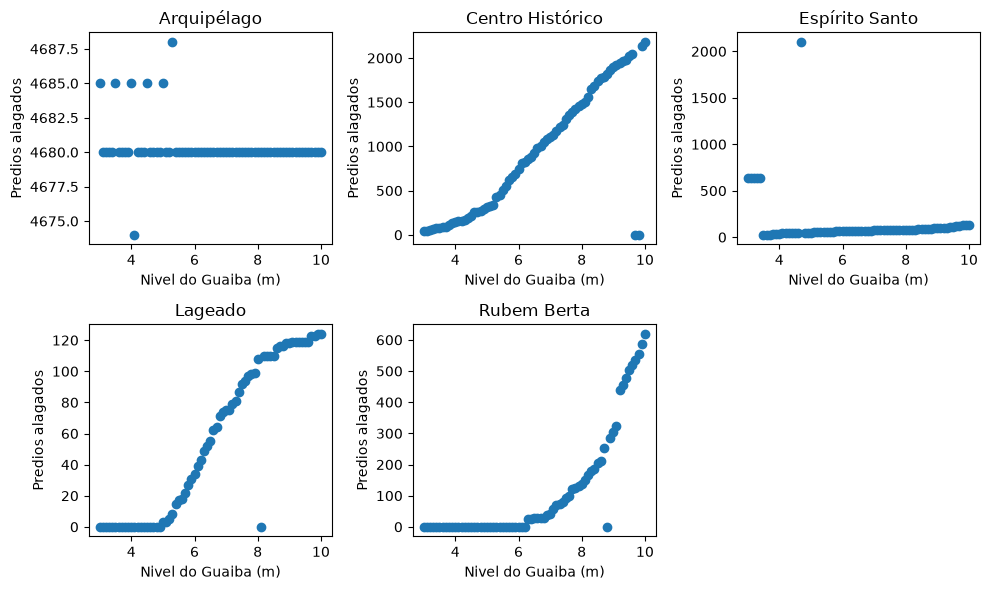

In [35]:
# Mostra um gráfico para cada bairro com queda, relacionando o nível do rio com os prédios alagados.
# O gráfico permite identificar visualmente qual valor está fora do padrão.
bairros_com_queda = quedas["bairro"].drop_duplicates().tolist()   # lista dos bairros com queda, sem repetição

plt.figure(figsize=(10,6))
posicao = 1   # posição do gráfico na tela, de 1 a 6
for bairro in bairros_com_queda:
    dados_do_bairro = df[df["bairro"] == bairro]
    plt.subplot(2,3,posicao)
    plt.scatter(dados_do_bairro["nivel"], dados_do_bairro["affected_buildings"])
    plt.title(bairro)
    plt.xlabel("Nivel do Guaiba (m)")
    plt.ylabel("Predios alagados")
    posicao = posicao + 1   # passa para a próxima posição
plt.tight_layout()   # ajusta o espaço entre os gráficos para que os textos não se sobreponham
plt.show()

In [36]:
# Guarda os valores originais antes da correção, para permitir a comparação depois
df["affected_buildings_original"] = df["affected_buildings"]

# Casos 1 e 2: valores errados isolados no meio da sequência.
# São os zeros no Lageado (8.1), no Rubem Berta (8.8) e no Centro Histórico (9.7 e 9.8),
# e o pico no Espírito Santo (4.7). Esses valores são apagados para serem preenchidos em seguida.
valores_errados = [
    ["Lageado", 8.1],
    ["Rubem Berta", 8.8],
    ["Centro Histórico", 9.7],
    ["Centro Histórico", 9.8],
    ["Espírito Santo", 4.7],
]
for bairro, nivel in valores_errados:
    linha_errada = np.where(df["bairro"] == bairro, df["nivel"] == nivel, False)   # identifica a linha desse bairro nesse nível
    df.loc[linha_errada, "affected_buildings"] = np.nan                             # apaga o valor, deixando o campo vazio

# Preenche os valores vazios por interpolação linear, separadamente em cada bairro.
# Cada valor vazio recebe o valor intermediário entre o nível anterior e o seguinte do mesmo bairro.
df["affected_buildings"] = df.groupby("bairro", group_keys=False)["affected_buildings"].apply(lambda predios: predios.interpolate(method="linear"))

# Caso 3: no Espírito Santo, os níveis de 3.0 a 3.4 têm cerca de 637 prédios alagados,
# mas no nível 3.5 o valor cai para 25 e depois cresce aos poucos. Como não existe nível anterior ao 3.0,
# não é possível interpolar, então esses níveis recebem o valor normal mais próximo, que é o do nível 3.5.
linha_3_5 = np.where(df["bairro"] == "Espírito Santo", df["nivel"] == 3.5, False)       # identifica a linha do Espírito Santo no nível 3.5
valor_normal = df.loc[linha_3_5, "affected_buildings"].iloc[0]                          # pega o valor dessa linha
linhas_erradas = np.where(df["bairro"] == "Espírito Santo", df["nivel"] < 3.5, False)   # identifica as linhas do Espírito Santo de 3.0 a 3.4
df.loc[linhas_erradas, "affected_buildings"] = valor_normal

# Converte para número inteiro, já que não existe fração de prédio
df["affected_buildings"] = df["affected_buildings"].astype(int)

# Marca as linhas que foram corrigidas e mostra quais foram
df["corrigido"] = df["affected_buildings"] != df["affected_buildings_original"]
print("Linhas corrigidas:", df["corrigido"].sum())
df[df["corrigido"] == True][["bairro", "nivel", "affected_buildings_original", "affected_buildings"]]

Linhas corrigidas: 10


,bairro,nivel,affected_buildings_original,affected_buildings
25,Espírito Santo,3.0,637,25
119,Espírito Santo,3.1,637,25
213,Espírito Santo,3.2,637,25
307,Espírito Santo,3.3,637,25
401,Espírito Santo,3.4,633,25
1623,Espírito Santo,4.7,2101,46
4842,Lageado,8.1,0,109
5522,Rubem Berta,8.8,0,268
6315,Centro Histórico,9.7,0,2076
6409,Centro Histórico,9.8,0,2103


In [37]:
# Verifica novamente se ainda existem quedas, repetindo o mesmo teste
quedas_depois = []
for bairro in df[df["nivel"] == 3.0]["bairro"].tolist():
    dados_do_bairro = df[df["bairro"] == bairro]
    niveis = dados_do_bairro["nivel"].tolist()
    predios = dados_do_bairro["affected_buildings"].tolist()
    for posicao in range(1, 71):
        if predios[posicao] < predios[posicao - 1]:
            quedas_depois.append([bairro, niveis[posicao], predios[posicao - 1], predios[posicao]])

quedas_depois = pd.DataFrame(quedas_depois, columns=["bairro", "nivel", "predios_antes", "predios_depois"])
print("Quedas que sobraram:", quedas_depois.shape[0])

# Caso 4: a única queda restante é a do Arquipélago, que oscila entre 4674 e 4688 prédios, uma variação menor que 0,3% do bairro.
# Os valores foram mantidos e a variação será informada como aviso,
# porque a diferença é muito pequena e não é possível saber qual valor é o correto.
quedas_depois

Quedas que sobraram: 6


,bairro,nivel,predios_antes,predios_depois
0,Arquipélago,3.1,4685,4680
1,Arquipélago,3.6,4685,4680
2,Arquipélago,4.1,4685,4674
3,Arquipélago,4.6,4685,4680
4,Arquipélago,5.1,4685,4680
5,Arquipélago,5.4,4688,4680


Cinza = valor original, azul = valor corrigido


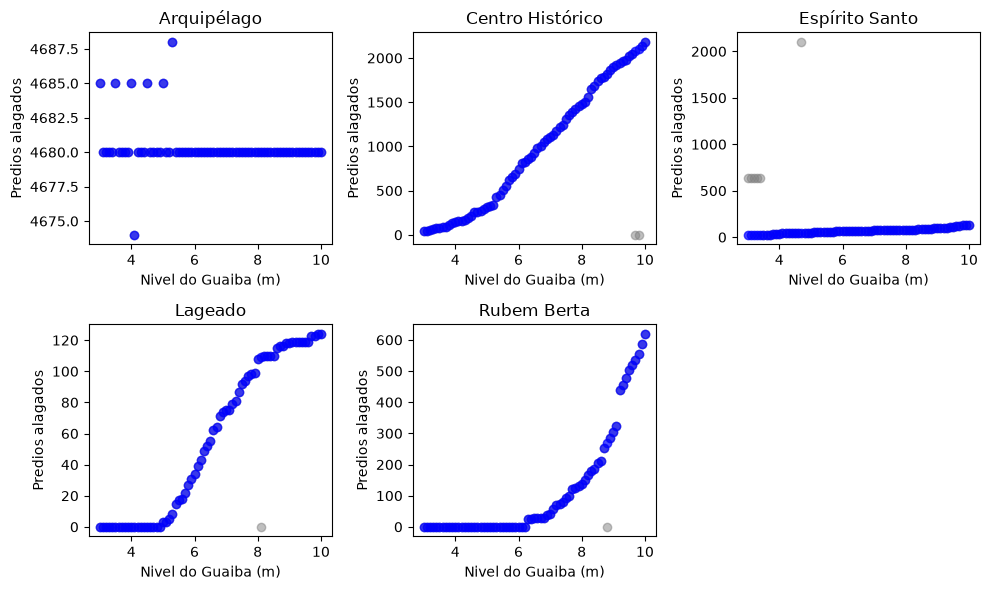

In [38]:
# Mostra os gráficos antes e depois da correção de cada bairro
print("Cinza = valor original, azul = valor corrigido")
plt.figure(figsize=(10,6))
posicao = 1
for bairro in bairros_com_queda:
    dados_do_bairro = df[df["bairro"] == bairro]
    plt.subplot(2,3,posicao)
    plt.scatter(dados_do_bairro["nivel"], dados_do_bairro["affected_buildings_original"], color="gray", alpha=0.5)
    plt.scatter(dados_do_bairro["nivel"], dados_do_bairro["affected_buildings"], color="blue", alpha=0.7)
    plt.title(bairro)
    plt.xlabel("Nivel do Guaiba (m)")
    plt.ylabel("Predios alagados")
    posicao = posicao + 1
plt.tight_layout()
plt.show()

In [39]:
# 7. Confere os cálculos
# A porcentagem e a população afetada são calculadas a partir das outras colunas.
# Aqui os cálculos são refeitos e comparados com os valores do arquivo.

# Calcula a porcentagem correta: prédios alagados divididos pelo total de prédios, vezes 100.
# São usados os prédios originais, para que a comparação com o arquivo seja justa.
df["percentage_calculada"] = df["affected_buildings_original"] / df["total_buildings"] * 100
df["diferenca_percentage"] = df["percentage"] - df["percentage_calculada"]   # diferença entre o valor do arquivo e o valor calculado

print(df["diferenca_percentage"].describe())   # a diferença fica sempre entre 0 e 1, ou seja, o arquivo nunca fica abaixo do valor correto

arquivo_acima_ou_igual = df["percentage"] >= df["percentage_calculada"]   # True quando o valor do arquivo é igual ou maior que o calculado
print(arquivo_acima_ou_igual.value_counts())   # todas as linhas dão True, o que mostra que a porcentagem do arquivo foi arredondada para cima

count    6674.000000
mean        0.196560
std         0.305596
min         0.000000
25%         0.000000
50%         0.000000
75%         0.347928
max         1.000000
Name: diferenca_percentage, dtype: float64
True    6674
Name: count, dtype: int64


In [40]:
# Calcula a população afetada correta: população vezes porcentagem, dividido por 100.
# A comparação usa a porcentagem do próprio arquivo.
df["populacao_calculada"] = df["population"] * df["percentage"] / 100
df["diferenca_populacao"] = df["affected_population"] - df["populacao_calculada"]   # diferença entre o valor do arquivo e o valor calculado

print(df["diferenca_populacao"].describe())   # a diferença também fica entre 0 e 1: a fórmula é a mesma, mas o resultado foi arredondado para cima

count    6674.000000
mean        0.198129
std         0.312000
min         0.000000
25%         0.000000
50%         0.000000
75%         0.387500
max         0.990000
Name: diferenca_populacao, dtype: float64


In [41]:
# Mostra um exemplo do problema: bairros com apenas um prédio alagado aparecem com 1% e com centenas de pessoas afetadas
exemplo = df[df["affected_buildings_original"] == 1]
exemplo[["bairro", "nivel", "affected_buildings_original", "total_buildings", "percentage", "percentage_calculada", "population", "affected_population"]].head()

,bairro,nivel,affected_buildings_original,total_buildings,percentage,percentage_calculada,population,affected_population
262,Santa Tereza,3.2,1,15906,1,0.006287,31358,314
376,Aberta dos Morros,3.4,1,4696,1,0.021295,9854,99
455,São João,3.4,1,3212,1,0.031133,10621,107
470,Aberta dos Morros,3.5,1,4696,1,0.021295,9854,99
893,Jardim São Pedro,3.9,1,1467,1,0.068166,3320,34


In [42]:
# Guarda os valores originais antes de recalcular, para permitir a comparação depois
df["percentage_original"] = df["percentage"]
df["affected_population_original"] = df["affected_population"]

# Recalcula a porcentagem e a população afetada com casas decimais, usando os prédios já corrigidos no passo 6
df["percentage"] = df["affected_buildings"] / df["total_buildings"] * 100
df["affected_population"] = (df["population"] * df["percentage"] / 100).astype(int)   # converte para número inteiro, já que não existe fração de pessoa

# Remove as colunas usadas apenas na conferência dos cálculos
df = df.drop(columns=["percentage_calculada", "diferenca_percentage", "populacao_calculada", "diferenca_populacao"])

# Mostra o mesmo exemplo depois do recálculo
exemplo = df[df["affected_buildings_original"] == 1]
exemplo[["bairro", "nivel", "affected_buildings", "total_buildings", "percentage_original", "percentage", "affected_population_original", "affected_population"]].head()

,bairro,nivel,affected_buildings,total_buildings,percentage_original,percentage,affected_population_original,affected_population
262,Santa Tereza,3.2,1,15906,1,0.006287,314,1
376,Aberta dos Morros,3.4,1,4696,1,0.021295,99,2
455,São João,3.4,1,3212,1,0.031133,107,3
470,Aberta dos Morros,3.5,1,4696,1,0.021295,99,2
893,Jardim São Pedro,3.9,1,1467,1,0.068166,34,2


Nivel 5.3 (o mais perto da enchente de 2024)
Pessoas afetadas no arquivo original: 138414
Pessoas afetadas depois da correcao: 136373
No grafico: cinza = original, azul = corrigido


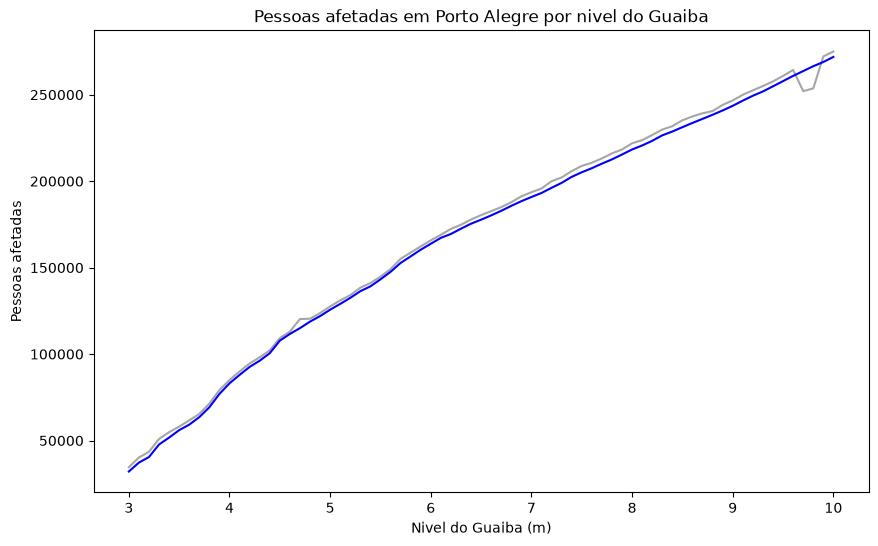

In [43]:
# Soma as pessoas afetadas de todos os bairros em cada nível, antes e depois da correção
total_original = df.groupby("nivel")["affected_population_original"].sum()
total_corrigido = df.groupby("nivel")["affected_population"].sum()

# Mostra os totais no nível 5.3, o mais próximo da enchente de 2024
print("Nivel 5.3 (o mais perto da enchente de 2024)")
print("Pessoas afetadas no arquivo original:", total_original.loc[5.3])
print("Pessoas afetadas depois da correcao:", total_corrigido.loc[5.3])
print("No grafico: cinza = original, azul = corrigido")

# Mostra o total de pessoas afetadas na cidade em cada nível do rio, antes e depois da correção
plt.figure(figsize=(10,6))
total_original.plot(color="gray", alpha=0.7)
total_corrigido.plot(color="blue")
plt.title("Pessoas afetadas em Porto Alegre por nivel do Guaiba")
plt.xlabel("Nivel do Guaiba (m)")
plt.ylabel("Pessoas afetadas")
plt.show()

In [44]:
# 8. Salva os dados limpos
# Seleciona as colunas que vão para o arquivo final.
# As colunas com "_original" e a coluna "corrigido" mostram o que foi alterado na limpeza.
colunas_finais = [
    "nivel",
    "bairro",
    "affected_buildings",
    "total_buildings",
    "percentage",
    "population",
    "affected_population",
    "corrigido",
    "affected_buildings_original",
    "percentage_original",
    "affected_population_original",
]
df_limpo = df[colunas_finais]

# Mostra as informações das colunas selecionadas
df_limpo.info()

<class 'pandas.DataFrame'>
RangeIndex: 6674 entries, 0 to 6673
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   nivel                         6674 non-null   float64
 1   bairro                        6674 non-null   str    
 2   affected_buildings            6674 non-null   int64  
 3   total_buildings               6674 non-null   int64  
 4   percentage                    6674 non-null   float64
 5   population                    6674 non-null   int64  
 6   affected_population           6674 non-null   int64  
 7   corrigido                     6674 non-null   bool   
 8   affected_buildings_original   6674 non-null   int64  
 9   percentage_original           6674 non-null   int64  
 10  affected_population_original  6674 non-null   int64  
dtypes: bool(1), float64(2), int64(7), str(1)
memory usage: 528.1 KB


In [45]:
# Salva a tabela limpa em formato JSON, com um registro para cada bairro em cada nível.
# O arquivo original continua sem alterações, na pasta dados/originais.
df_limpo.to_json("../dados/processados/inct_limpo.json", orient="records", force_ascii=False, indent=2)   # force_ascii=False mantém os acentos

In [46]:
# Abre o arquivo salvo para verificar se ele foi gravado corretamente
with open("../dados/processados/inct_limpo.json", encoding="utf-8") as arquivo:
    dados_limpos = json.load(arquivo)

df_conferencia = pd.DataFrame(dados_limpos)
print(df_conferencia.shape)   # o esperado são 6674 linhas e 11 colunas
df_conferencia.head()

(6674, 11)


,nivel,bairro,affected_buildings,total_buildings,percentage,population,affected_population,corrigido,affected_buildings_original,percentage_original,affected_population_original
0,3.0,Aberta dos Morros,0,4696,0.000000,9854,0,False,0,0,0
1,3.0,Agronomia,0,1771,0.000000,2677,0,False,0,0,0
2,3.0,Anchieta,28,589,4.753820,791,37,False,28,5,40
3,3.0,Arquipélago,4685,4688,99.936007,6411,6406,False,4685,100,6411
4,3.0,Auxiliadora,0,1995,0.000000,8909,0,False,0,0,0
